# Homework 11 — CLIP Image-Text Similarity and Zero-Shot Classification





In [1]:

from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount('/content/drive')

# Create the main assignment folder
project_dir = Path('/content/drive/MyDrive/Homework11_CLIP')
output_dir = project_dir / 'outputs'

# Create folders for different results
dataset_dir = output_dir / 'dataset'
embeddings_dir = output_dir / 'embeddings'
similarity_dir = output_dir / 'similarity'
classification_dir = output_dir / 'classification'

for folder in [dataset_dir, embeddings_dir,
               similarity_dir, classification_dir]:
    folder.mkdir(parents=True, exist_ok=True)

print("Google Drive connected successfully!")
print("Main output folder:", output_dir)

print("\nOutput folders created:")
for folder in [dataset_dir, embeddings_dir,
               similarity_dir, classification_dir]:
    print(folder.name, "- Ready")


Mounted at /content/drive
Google Drive connected successfully!
Main output folder: /content/drive/MyDrive/Homework11_CLIP/outputs

Output folders created:
dataset - Ready
embeddings - Ready
similarity - Ready
classification - Ready


## Step 1: Import Libraries and Set Up the Environment

In this step, I import the Python libraries needed for the assignment.

- **PyTorch:** Runs the CLIP model using a GPU when available.
- **Torchvision:** Downloads and loads CIFAR-10 images.
- **Transformers:** Provides the pretrained CLIP model and its processor.
- **NumPy:** Helps with numerical operations.
- **Matplotlib and Seaborn:** Help visualize images and the confusion matrix.
- **Scikit-learn:** Calculates classification accuracy and evaluation metrics.

I will also check whether Google Colab has a GPU available for faster execution.

In [2]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import accuracy_score, confusion_matrix

# Check whether a GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
Device: cuda
GPU: NVIDIA L4


## Step 3: Load CIFAR-10 and Select 100 Images per Class

CIFAR-10 is an image dataset containing 10 different classes, including airplanes, automobiles, birds, cats, deer, dogs, frogs, horses, ships, and trucks.

For this assignment, I use the CIFAR-10 test dataset and select exactly 100 images from each class, giving a total of 1,000 images.

I use a balanced number of images from each class so that the comparison is fair.

I also save the selected image labels and the number of images per class as CSV files in Google Drive. This helps keep a record of the dataset used in the assignment.

In [5]:

# Load CIFAR-10 test dataset
dataset = CIFAR10(
    root="./data",
    train=False,
    download=True
)

class_names = dataset.classes

# Select 100 images from each class
images = []
labels = []
class_counts = [0] * 10

for image, label in dataset:

    if class_counts[label] < 100:
        images.append(image)
        labels.append(label)
        class_counts[label] += 1

    if all(count == 100 for count in class_counts):
        break

# Check the selected images
print("Total selected images:", len(images))
print("\nImages per class:")

for name, count in zip(class_names, class_counts):
    print(f"{name}: {count}")

assert len(images) == 1000
assert all(count == 100 for count in class_counts)

# Save the selected image labels
labels_df = pd.DataFrame({
    "image_index": range(len(images)),
    "class_id": labels,
    "class_name": [class_names[label] for label in labels]
})

labels_df.to_csv(
    dataset_dir / "selected_labels.csv",
    index=False
)

# Save the number of images per class
summary_df = pd.DataFrame({
    "class_name": class_names,
    "image_count": class_counts
})

summary_df.to_csv(
    dataset_dir / "class_distribution.csv",
    index=False
)

print("\nDataset information saved to Google Drive!")
print("Files saved:")
print("selected_labels.csv")
print("class_distribution.csv")


Total selected images: 1000

Images per class:
airplane: 100
automobile: 100
bird: 100
cat: 100
deer: 100
dog: 100
frog: 100
horse: 100
ship: 100
truck: 100

Dataset information saved to Google Drive!
Files saved:
selected_labels.csv
class_distribution.csv


## Step 4: Visualize Sample Images from CIFAR-10

Before using the CLIP model, I display one sample image from each of the 10 CIFAR-10 classes.

This helps me understand what the dataset looks like and verify that images from all classes were selected correctly.

CIFAR-10 images have a resolution of 32 × 32 pixels, so they may look slightly blurry when enlarged.

I also save this visualization as a PNG file in Google Drive for future reference.

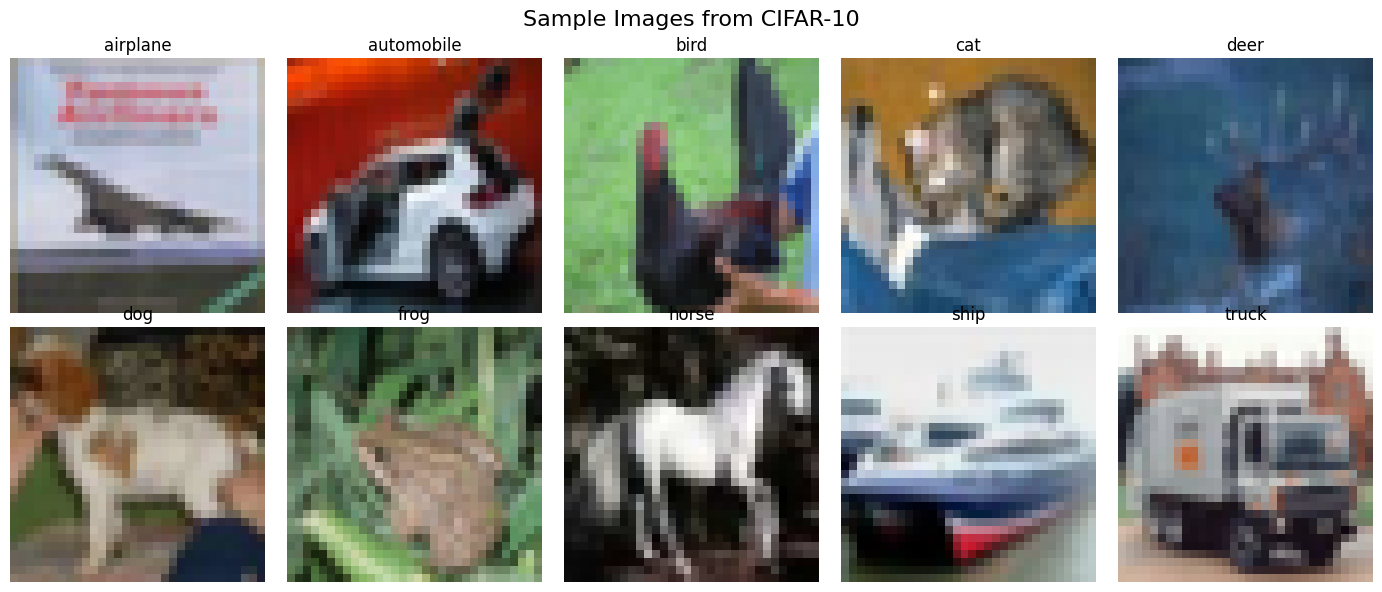

Sample image visualization saved!
File location: /content/drive/MyDrive/Homework11_CLIP/outputs/dataset/sample_images.png


In [6]:

# Display one sample image from each class
plt.figure(figsize=(14, 6))

for class_id in range(10):

    # Find the first image belonging to this class
    image_index = labels.index(class_id)

    plt.subplot(2, 5, class_id + 1)
    plt.imshow(images[image_index])
    plt.title(class_names[class_id])
    plt.axis("off")

plt.suptitle("Sample Images from CIFAR-10", fontsize=16)
plt.tight_layout()

# Save the figure to Google Drive
save_path = dataset_dir / "sample_images.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")

# Display the figure
plt.show()

print("Sample image visualization saved!")
print("File location:", save_path)


## Step 5: Load the Pretrained CLIP Model

In this step, I load the pretrained CLIP model using Hugging Face Transformers.

CLIP (Contrastive Language–Image Pretraining) uses an image encoder and a text encoder to convert images and captions into numerical representations called embeddings.

I use the `openai/clip-vit-base-patch32` model, which can compare images and text without additional training.

I also load the CLIP processor to prepare images and text in the format expected by the model.

The model is moved to the GPU and set to evaluation mode because this assignment does not require fine-tuning.

In [7]:

# Load the pretrained CLIP model and processor
model_name = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_name)
processor = CLIPProcessor.from_pretrained(model_name)

# Move the model to the GPU
model = model.to(device)

# Use evaluation mode (no training)
model.eval()

print("CLIP model loaded successfully!")
print("Model:", model_name)
print("Device:", device)


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully!
Model: openai/clip-vit-base-patch32
Device: cuda


## Step 6: Define Text Captions for CIFAR-10

In this step, I create 10 text captions, one for each CIFAR-10 class.

CLIP compares images with text descriptions, so I use the simple format "a photo of a ..." for all captions.

Using the same caption format makes the comparison consistent across classes.

These captions will be used for both image-text similarity analysis and zero-shot classification.

I also save the captions in a CSV file so I can keep a record of the exact descriptions used in the experiment.

In [8]:

# Define one caption for each CIFAR-10 class
captions = [
    "a photo of an airplane",
    "a photo of an automobile",
    "a photo of a bird",
    "a photo of a cat",
    "a photo of a deer",
    "a photo of a dog",
    "a photo of a frog",
    "a photo of a horse",
    "a photo of a ship",
    "a photo of a truck"
]

# Display the captions
print("Total captions:", len(captions))
print("\nCIFAR-10 Captions:")

for name, caption in zip(class_names, captions):
    print(f"{name}: {caption}")

# Save captions to CSV
captions_df = pd.DataFrame({
    "class_name": class_names,
    "caption": captions
})

captions_path = dataset_dir / "captions.csv"
captions_df.to_csv(captions_path, index=False)

print("\nCaptions saved successfully!")
print("File location:", captions_path)


Total captions: 10

CIFAR-10 Captions:
airplane: a photo of an airplane
automobile: a photo of an automobile
bird: a photo of a bird
cat: a photo of a cat
deer: a photo of a deer
dog: a photo of a dog
frog: a photo of a frog
horse: a photo of a horse
ship: a photo of a ship
truck: a photo of a truck

Captions saved successfully!
File location: /content/drive/MyDrive/Homework11_CLIP/outputs/dataset/captions.csv


## Step 7: Preprocess Images and Extract Normalized Image Embeddings

In this step, I preprocess all 1,000 CIFAR-10 images using the CLIP processor.

The processor resizes and normalizes each image into the format expected by CLIP. I process the images in batches of 32 to avoid using too much GPU memory.

I then use CLIP's image encoder and projection layer to extract image embeddings. Each image is represented by 512 numerical values.

I apply L2 normalization so that each embedding has a length of 1. This allows me to compare image and text embeddings using cosine similarity.

Finally, I save the normalized image embeddings as a NumPy file in Google Drive so they can be reused without extracting them again.

In [9]:

# Extract embeddings from all 1,000 images
batch_size = 32
image_embeddings = []

for start in range(0, len(images), batch_size):

    # Select a batch of images
    batch_images = images[start:start + batch_size]

    # Preprocess the images
    inputs = processor(
        images=batch_images,
        return_tensors="pt"
    ).to(device)

    # Extract image features without training
    with torch.no_grad():

        vision_outputs = model.vision_model(
            pixel_values=inputs["pixel_values"]
        )

        embeddings = model.visual_projection(
            vision_outputs.pooler_output
        )

        # Normalize the image embeddings
        embeddings = embeddings / embeddings.norm(
            dim=-1, keepdim=True
        )

    # Store the embeddings on CPU
    image_embeddings.append(embeddings.cpu())

# Combine all batches
image_embeddings = torch.cat(image_embeddings, dim=0)

# Save embeddings to Google Drive
save_path = embeddings_dir / "image_embeddings.npy"
np.save(save_path, image_embeddings.numpy())

# Verify the results
print("Total images processed:", len(images))
print("Image embeddings shape:", image_embeddings.shape)
print("First embedding length:", round(image_embeddings[0].norm().item(), 4))

print("\nImage embeddings saved successfully!")
print("File location:", save_path)
print("File exists:", save_path.exists())


Total images processed: 1000
Image embeddings shape: torch.Size([1000, 512])
First embedding length: 1.0

Image embeddings saved successfully!
File location: /content/drive/MyDrive/Homework11_CLIP/outputs/embeddings/image_embeddings.npy
File exists: True


## Step 8: Extract and Normalize Text Embeddings

In this step, I use CLIP's text encoder to convert the 10 CIFAR-10 captions into numerical embeddings.

First, I tokenize the captions using the CLIP processor. Then, I use the text encoder and projection layer to obtain text embeddings in the same 512-dimensional space as the image embeddings.

I apply L2 normalization so that each text embedding has a length of 1.

Finally, I save the normalized text embeddings as a NumPy file in Google Drive. These embeddings will be used to calculate cosine similarity between images and captions.

In [10]:

# Prepare all 10 text captions
text_inputs = processor(
    text=captions,
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

# Extract text embeddings without training
with torch.no_grad():

    # Get features from CLIP's text encoder
    text_outputs = model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs["attention_mask"]
    )

    # Project into the shared embedding space
    text_embeddings = model.text_projection(
        text_outputs.pooler_output
    )

    # Normalize the text embeddings
    text_embeddings = text_embeddings / text_embeddings.norm(
        dim=-1, keepdim=True
    )

# Move the embeddings to CPU
text_embeddings = text_embeddings.cpu()

# Save to Google Drive
save_path = embeddings_dir / "text_embeddings.npy"
np.save(save_path, text_embeddings.numpy())

# Verify the results
print("Total captions processed:", len(captions))
print("Text embeddings shape:", text_embeddings.shape)
print("First embedding length:", round(text_embeddings[0].norm().item(), 4))

print("\nText embeddings saved successfully!")
print("File location:", save_path)
print("File exists:", save_path.exists())


Total captions processed: 10
Text embeddings shape: torch.Size([10, 512])
First embedding length: 1.0

Text embeddings saved successfully!
File location: /content/drive/MyDrive/Homework11_CLIP/outputs/embeddings/text_embeddings.npy
File exists: True


## Step 9: Calculate Cosine Similarity Between Images and Captions

In this step, I calculate the cosine similarity between all 1,000 CIFAR-10 images and the 10 text captions.

Since the image and text embeddings are already normalized, I can calculate cosine similarity using matrix multiplication.

The result is a matrix with 1,000 rows and 10 columns. Each row represents an image, while each column represents one of the text captions.

A higher similarity score means that CLIP finds the image and caption more closely related.

I save the similarity scores in both NumPy (`.npy`) and CSV (`.csv`) formats so I can reuse and analyze them later.

In [11]:

# Calculate cosine similarity between images and captions
similarity_scores = image_embeddings @ text_embeddings.T

print("Similarity matrix shape:", similarity_scores.shape)
print("Total similarity scores:", similarity_scores.numel())

# Save similarity scores as a NumPy file
npy_path = similarity_dir / "similarity_scores.npy"
np.save(npy_path, similarity_scores.numpy())

# Create a readable CSV table
similarity_df = pd.DataFrame(
    similarity_scores.numpy(),
    columns=class_names
)

# Include image index and actual class
similarity_df.insert(
    0, "actual_class",
    [class_names[label] for label in labels]
)

similarity_df.insert(
    0, "image_index",
    range(len(images))
)

# Save the CSV file
csv_path = similarity_dir / "similarity_scores.csv"
similarity_df.to_csv(csv_path, index=False)

# Show similarity scores for the first image
print("\nFirst image's actual class:", class_names[labels[0]])
print("\nSimilarity scores for the first image:")

for name, score in zip(class_names, similarity_scores[0]):
    print(f"{name}: {score.item():.4f}")

# Find the best matching caption
best_match = similarity_scores[0].argmax().item()

print("\nHighest similarity caption:", captions[best_match])
print("Highest similarity score:",
      round(similarity_scores[0, best_match].item(), 4))

# Verify and display saved files
assert similarity_scores.shape == (1000, 10)

print("\nFiles saved successfully!")
print("NumPy file:", npy_path)
print("CSV file:", csv_path)
print("NumPy file exists:", npy_path.exists())
print("CSV file exists:", csv_path.exists())


Similarity matrix shape: torch.Size([1000, 10])
Total similarity scores: 10000

First image's actual class: cat

Similarity scores for the first image:
airplane: 0.1824
automobile: 0.1902
bird: 0.1997
cat: 0.2143
deer: 0.1877
dog: 0.2076
frog: 0.1912
horse: 0.1901
ship: 0.2005
truck: 0.1750

Highest similarity caption: a photo of a cat
Highest similarity score: 0.2143

Files saved successfully!
NumPy file: /content/drive/MyDrive/Homework11_CLIP/outputs/similarity/similarity_scores.npy
CSV file: /content/drive/MyDrive/Homework11_CLIP/outputs/similarity/similarity_scores.csv
NumPy file exists: True
CSV file exists: True


## Step 10: Visualize Images with Their Cosine Similarity Scores

In this step, I visualize the images that have the highest cosine similarity with each of the 10 CIFAR-10 captions.

For every caption, I compare its similarity scores against all 1,000 images and select the two highest-scoring images.

I display each selected image with its actual class label and cosine similarity score.

This helps me understand how well CLIP matches images with text descriptions and whether the highest-scoring images belong to the expected categories.

I also save the visualization as a high-resolution PNG file in Google Drive.

Although only 20 images are displayed, the similarity analysis includes all 1,000 images.

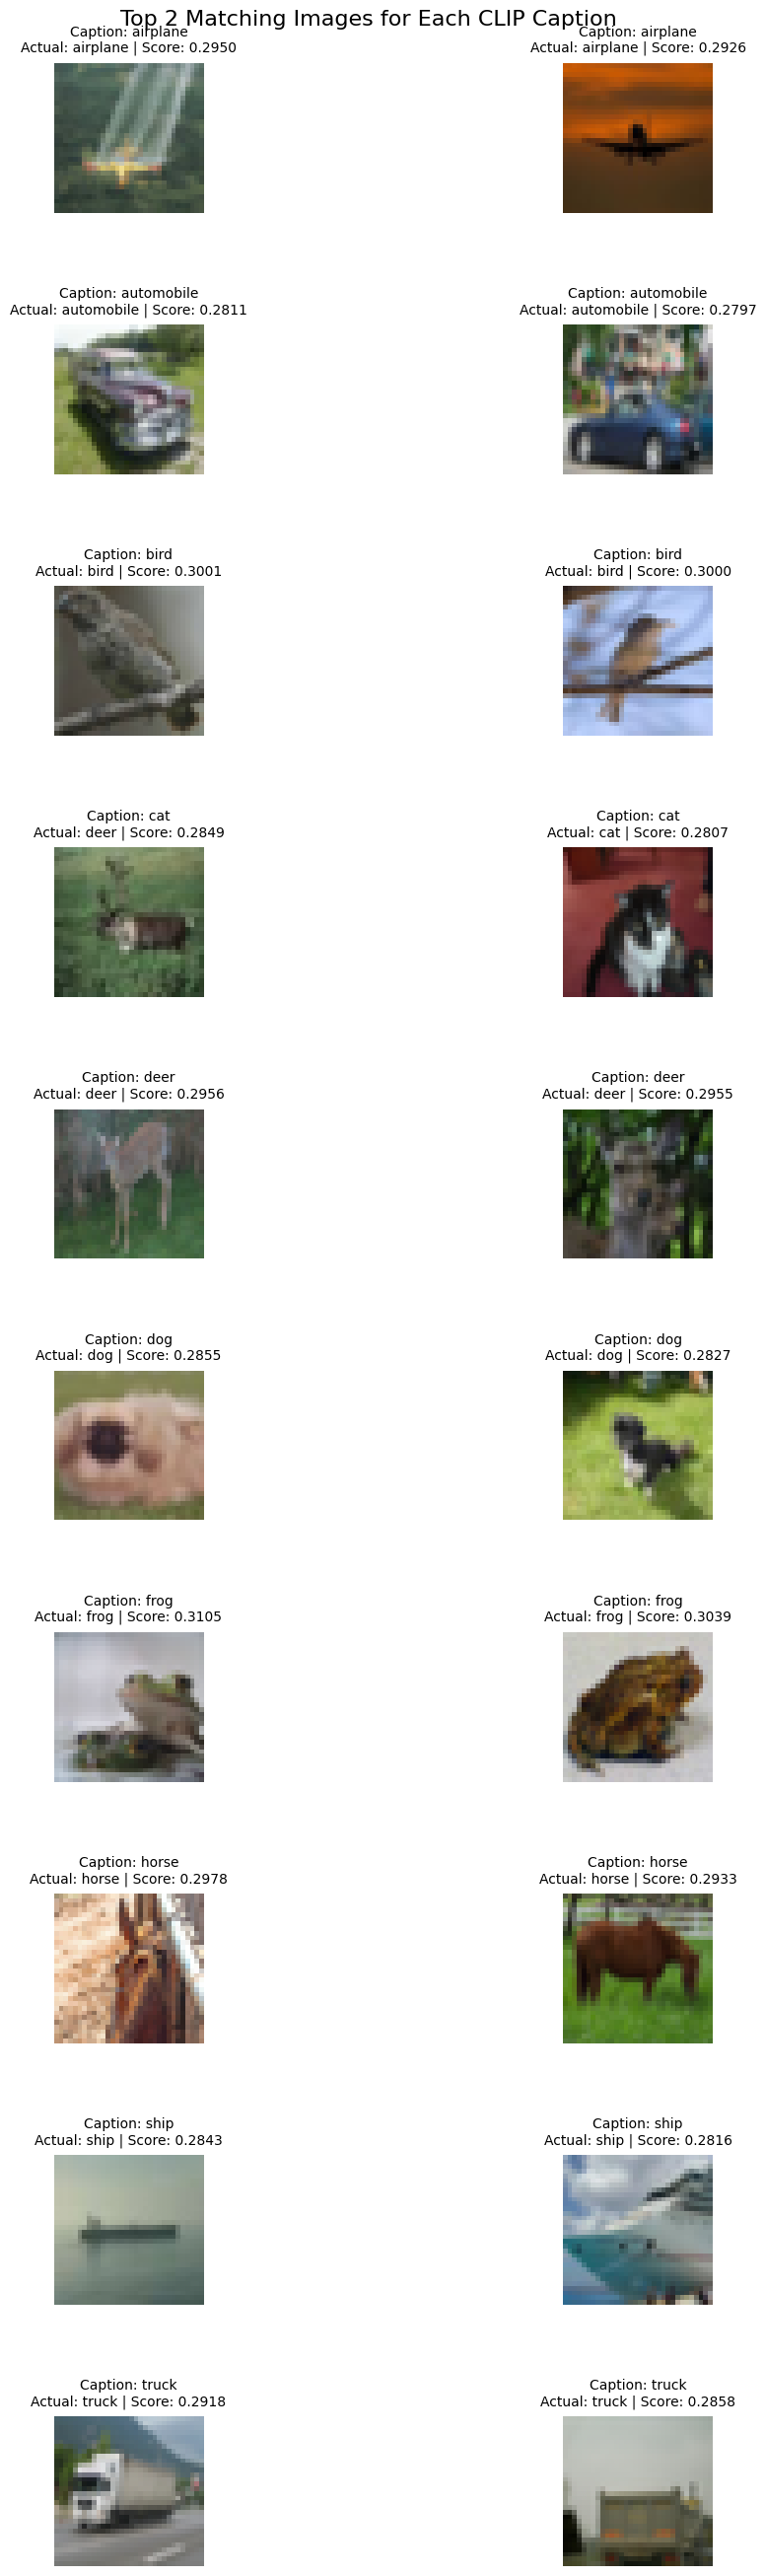

Visualization saved successfully!
File location: /content/drive/MyDrive/Homework11_CLIP/outputs/similarity/top_matching_images.png
File exists: True


In [12]:

# Display the top 2 matching images for each caption
fig, axes = plt.subplots(10, 2, figsize=(12, 27))

for class_id in range(10):

    # Similarity scores for the current caption
    scores = similarity_scores[:, class_id]

    # Find the top 2 matching images
    top_indices = torch.topk(scores, 2).indices.tolist()

    for j, image_index in enumerate(top_indices):

        ax = axes[class_id, j]
        ax.imshow(images[image_index])

        actual_class = class_names[labels[image_index]]
        score = scores[image_index].item()

        ax.set_title(
            f"Caption: {class_names[class_id]}\n"
            f"Actual: {actual_class} | Score: {score:.4f}",
            fontsize=10,
            pad=8
        )

        ax.axis("off")

fig.suptitle(
    "Top 2 Matching Images for Each CLIP Caption",
    fontsize=16
)

# Adjust spacing to avoid overlapping titles
plt.subplots_adjust(
    top=0.96,
    bottom=0.02,
    hspace=0.75,
    wspace=0.25
)

# Save visualization to Google Drive
save_path = similarity_dir / "top_matching_images.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Visualization saved successfully!")
print("File location:", save_path)
print("File exists:", save_path.exists())


## Step 11: Compare Average Cosine Similarity Across CIFAR-10 Classes

In this step, I calculate the average cosine similarity between each class caption and the 100 images belonging to that class.

For example, I calculate the average similarity between the caption "a photo of a cat" and the 100 cat images. I repeat this process for all 10 classes.

I display the average similarity scores in a bar chart to compare the different categories.

This helps me understand which image categories have stronger image-text similarity according to CLIP.

I also save the numerical results as a CSV file and the visualization as a PNG file in Google Drive.

A higher average similarity indicates stronger image-text alignment, but it does not necessarily mean higher classification accuracy.

Average Cosine Similarity by Class

airplane: 0.2577
automobile: 0.2579
bird: 0.2699
cat: 0.2607
deer: 0.2672
dog: 0.2594
frog: 0.2542
horse: 0.2722
ship: 0.2539
truck: 0.2541


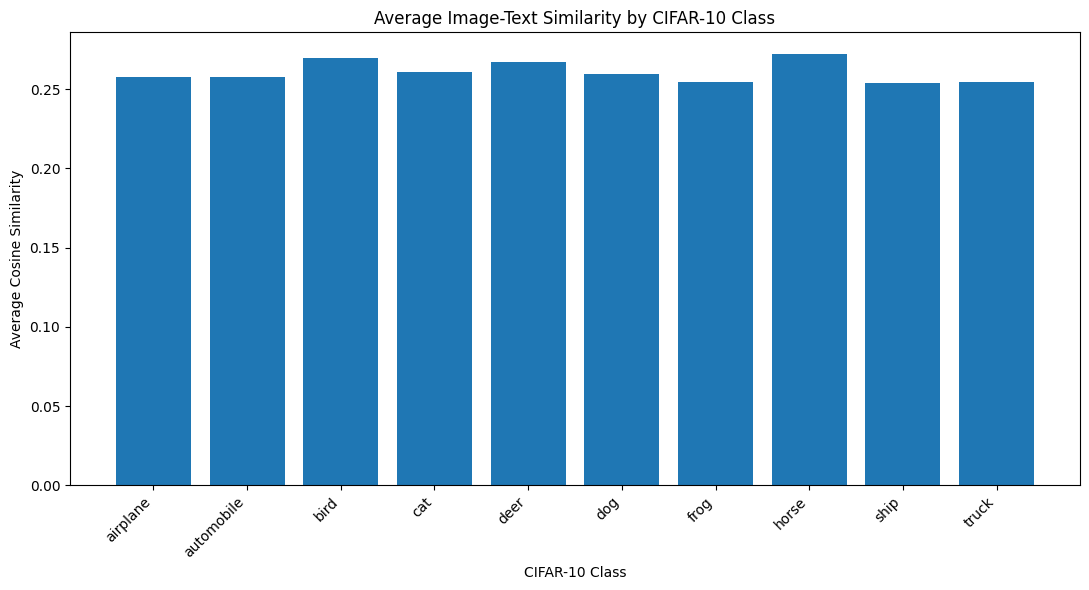


Files saved successfully!
CSV: /content/drive/MyDrive/Homework11_CLIP/outputs/similarity/average_similarity.csv
PNG: /content/drive/MyDrive/Homework11_CLIP/outputs/similarity/average_similarity.png
CSV exists: True
PNG exists: True


In [13]:

# Calculate average cosine similarity for each class
average_scores = []

for class_id in range(10):

    # Find images belonging to this class
    class_indices = [
        i for i, label in enumerate(labels)
        if label == class_id
    ]

    # Similarity with the correct class caption
    class_scores = similarity_scores[class_indices, class_id]

    # Calculate the average
    average_scores.append(class_scores.mean().item())

# Display average similarity scores
print("Average Cosine Similarity by Class\n")

for name, score in zip(class_names, average_scores):
    print(f"{name}: {score:.4f}")

# Save numerical results as CSV
average_df = pd.DataFrame({
    "class_name": class_names,
    "average_cosine_similarity": average_scores
})

csv_path = similarity_dir / "average_similarity.csv"
average_df.to_csv(csv_path, index=False)

# Create the bar chart
plt.figure(figsize=(11, 6))

plt.bar(class_names, average_scores)

plt.title("Average Image-Text Similarity by CIFAR-10 Class")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Average Cosine Similarity")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save the figure
png_path = similarity_dir / "average_similarity.png"
plt.savefig(png_path, dpi=300, bbox_inches="tight")

plt.show()

print("\nFiles saved successfully!")
print("CSV:", csv_path)
print("PNG:", png_path)
print("CSV exists:", csv_path.exists())
print("PNG exists:", png_path.exists())


## Step 12: Part 1 — Observations and Findings

In Part 1, I used the pretrained CLIP model to compare 1,000 CIFAR-10 images with 10 text captions, producing 10,000 cosine similarity scores.

After visualizing the top matching images and comparing average similarity scores, I observed the following:

1. The horse class had the highest average cosine similarity (0.2722), followed by bird (0.2699).
2. The ship class had the lowest average similarity (0.2539).
3. All 10 classes had relatively similar average scores, ranging from approximately 0.254 to 0.272.
4. CLIP identified matching images for several captions, including airplane, automobile, and bird.
5. In the earlier visualization, the highest-scoring image for the cat caption belonged to the deer class, showing that a high similarity score does not always mean a correct class match.

Overall, CLIP was able to compare images and text without additional training. However, image quality, visual similarities between classes, and caption wording can affect the results.

These findings describe image-text similarity. Classification accuracy will be evaluated separately in Part 2.

# Part 2: Zero-Shot Classification Using CLIP

## Step 13: Generate Zero-Shot Predictions

In this step, I use CLIP to classify the 1,000 CIFAR-10 images without training the model on this dataset.

For each image, I compare its similarity scores against all 10 text captions and select the caption with the highest cosine similarity as the predicted class.

I compare the predicted classes with the actual CIFAR-10 labels to calculate the overall classification accuracy.

I also save the predictions and evaluation summary as CSV files in Google Drive so the results can be reviewed later.

In [14]:

# Predict the class with the highest similarity score
predicted_labels = similarity_scores.argmax(dim=1).numpy()

# Convert actual labels to a NumPy array
actual_labels = np.array(labels)

# Calculate overall accuracy
overall_accuracy = accuracy_score(actual_labels, predicted_labels)

correct_predictions = np.sum(actual_labels == predicted_labels)
incorrect_predictions = len(actual_labels) - correct_predictions

print("Total images:", len(actual_labels))
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)
print(f"Overall zero-shot accuracy: {overall_accuracy * 100:.2f}%")

# Save predictions as CSV
predictions_df = pd.DataFrame({
    "image_index": range(len(images)),
    "actual_class": [class_names[i] for i in actual_labels],
    "predicted_class": [class_names[i] for i in predicted_labels],
    "correct": actual_labels == predicted_labels
})

predictions_path = classification_dir / "predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

# Save the overall accuracy summary
summary_df = pd.DataFrame({
    "total_images": [len(actual_labels)],
    "correct_predictions": [correct_predictions],
    "incorrect_predictions": [incorrect_predictions],
    "overall_accuracy_percent": [overall_accuracy * 100]
})

summary_path = classification_dir / "overall_accuracy.csv"
summary_df.to_csv(summary_path, index=False)

print("\nFiles saved successfully!")
print("Predictions:", predictions_path)
print("Accuracy summary:", summary_path)
print("Predictions file exists:", predictions_path.exists())
print("Summary file exists:", summary_path.exists())


Total images: 1000
Correct predictions: 903
Incorrect predictions: 97
Overall zero-shot accuracy: 90.30%

Files saved successfully!
Predictions: /content/drive/MyDrive/Homework11_CLIP/outputs/classification/predictions.csv
Accuracy summary: /content/drive/MyDrive/Homework11_CLIP/outputs/classification/overall_accuracy.csv
Predictions file exists: True
Summary file exists: True


## Step 14: Calculate Per-Class Zero-Shot Accuracy

In this step, I calculate the classification accuracy for each of the 10 CIFAR-10 classes.

Although the overall accuracy shows how well CLIP performed across all images, per-class accuracy helps me understand which categories the model recognizes better.

For each class, I count the number of correctly predicted images and divide it by the total number of images in that class.

Since I selected 100 images from each class, the formula is:

**Per-Class Accuracy (%) = (Correctly Classified Images / 100) × 100**

I visualize the accuracy values using a bar chart and save both the numerical results and the figure in Google Drive.

This helps identify the best-performing and most difficult classes for zero-shot classification.

Per-Class Zero-Shot Accuracy

airplane: 91.00% (91/100)
automobile: 98.00% (98/100)
bird: 92.00% (92/100)
cat: 89.00% (89/100)
deer: 72.00% (72/100)
dog: 87.00% (87/100)
frog: 82.00% (82/100)
horse: 100.00% (100/100)
ship: 99.00% (99/100)
truck: 93.00% (93/100)


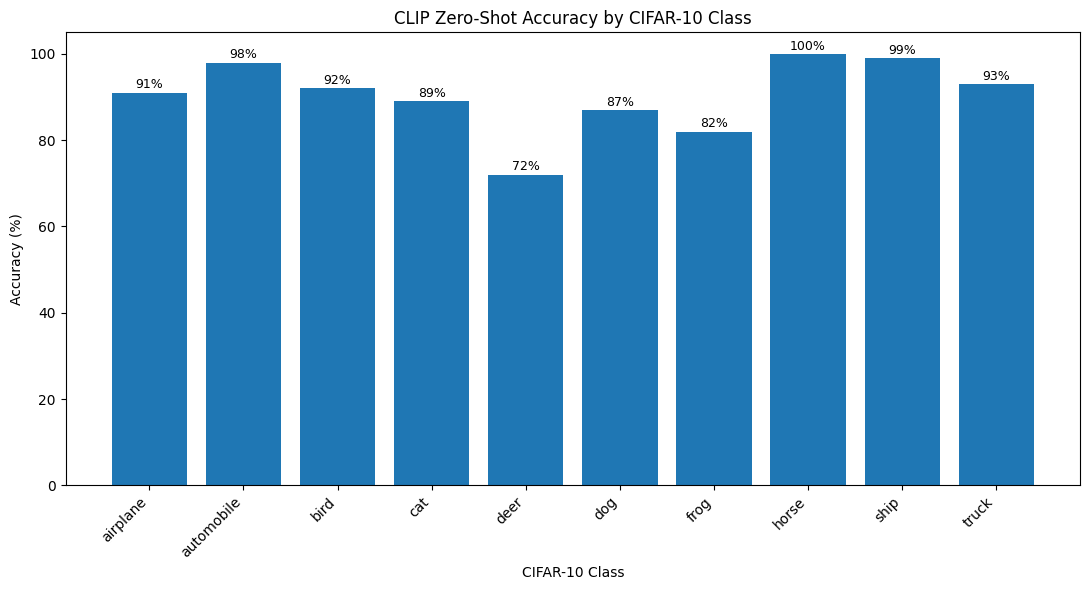


Files saved successfully!
CSV: /content/drive/MyDrive/Homework11_CLIP/outputs/classification/per_class_accuracy.csv
PNG: /content/drive/MyDrive/Homework11_CLIP/outputs/classification/per_class_accuracy.png
CSV exists: True
PNG exists: True


In [15]:

# Calculate accuracy for each CIFAR-10 class
per_class_accuracy = []
correct_counts = []

print("Per-Class Zero-Shot Accuracy\n")

for class_id in range(10):

    # Select images from the current class
    class_mask = actual_labels == class_id

    # Count correct predictions
    correct = np.sum(
        predicted_labels[class_mask] == actual_labels[class_mask]
    )

    total = np.sum(class_mask)
    accuracy = (correct / total) * 100

    correct_counts.append(int(correct))
    per_class_accuracy.append(accuracy)

    print(f"{class_names[class_id]}: {accuracy:.2f}% ({correct}/{total})")

# Save per-class results as CSV
accuracy_df = pd.DataFrame({
    "class_name": class_names,
    "total_images": [100] * 10,
    "correct_predictions": correct_counts,
    "accuracy_percent": per_class_accuracy
})

csv_path = classification_dir / "per_class_accuracy.csv"
accuracy_df.to_csv(csv_path, index=False)

# Create the accuracy bar chart
plt.figure(figsize=(11, 6))

plt.bar(class_names, per_class_accuracy)

plt.title("CLIP Zero-Shot Accuracy by CIFAR-10 Class")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.xticks(rotation=45, ha="right")

# Show accuracy values above each bar
for i, accuracy in enumerate(per_class_accuracy):
    plt.text(i, accuracy + 1, f"{accuracy:.0f}%",
             ha="center", fontsize=9)

plt.tight_layout()

# Save the figure
png_path = classification_dir / "per_class_accuracy.png"
plt.savefig(png_path, dpi=300, bbox_inches="tight")

plt.show()

print("\nFiles saved successfully!")
print("CSV:", csv_path)
print("PNG:", png_path)
print("CSV exists:", csv_path.exists())
print("PNG exists:", png_path.exists())


## Step 15: Generate and Analyze the Confusion Matrix

In this step, I create a confusion matrix to evaluate CLIP's zero-shot classification performance on the 1,000 CIFAR-10 images.

A confusion matrix compares the actual class labels with the predicted class labels.

Each row represents the actual class, and each column represents the predicted class. The diagonal values show the number of correctly classified images, while the other values show classification mistakes.

I use a heatmap to visualize the confusion matrix and identify which classes CLIP tends to confuse.

I also save the confusion matrix as a CSV file and a high-resolution PNG image in Google Drive for future reference.

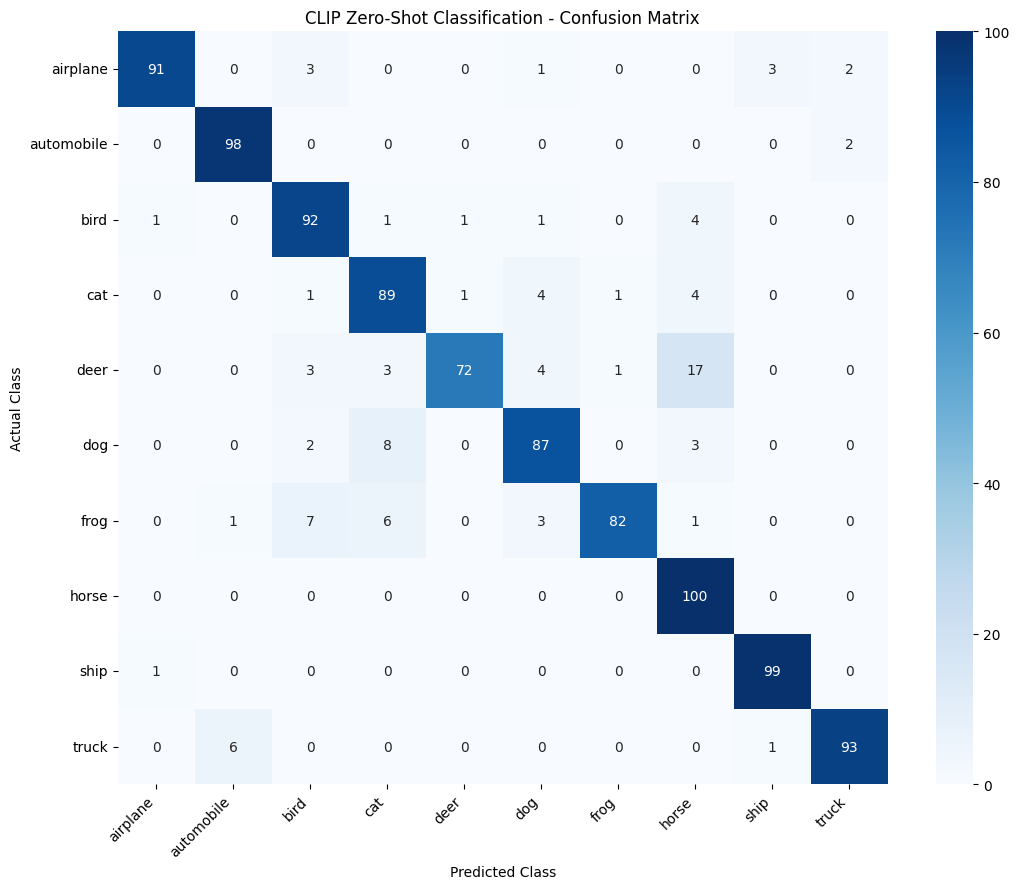

Confusion matrix shape: (10, 10)
Total images evaluated: 1000
Correct predictions: 903
Incorrect predictions: 97

Files saved successfully!
CSV: /content/drive/MyDrive/Homework11_CLIP/outputs/classification/confusion_matrix.csv
PNG: /content/drive/MyDrive/Homework11_CLIP/outputs/classification/confusion_matrix.png
CSV exists: True
PNG exists: True


In [16]:

# Calculate the confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=range(10)
)

# Save the confusion matrix as CSV
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.index.name = "Actual Class"
cm_df.columns.name = "Predicted Class"

csv_path = classification_dir / "confusion_matrix.csv"
cm_df.to_csv(csv_path)

# Create the confusion matrix heatmap
plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CLIP Zero-Shot Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the heatmap as PNG
png_path = classification_dir / "confusion_matrix.png"
plt.savefig(png_path, dpi=300, bbox_inches="tight")

plt.show()

# Verify classification results
print("Confusion matrix shape:", cm.shape)
print("Total images evaluated:", cm.sum())
print("Correct predictions:", np.trace(cm))
print("Incorrect predictions:", cm.sum() - np.trace(cm))

print("\nFiles saved successfully!")
print("CSV:", csv_path)
print("PNG:", png_path)
print("CSV exists:", csv_path.exists())
print("PNG exists:", png_path.exists())


##  Failure Analysis of CLIP Predictions

In this step, I analyze the images that CLIP classified incorrectly.

Although the model achieved an overall accuracy of 90.30%, it made 97 incorrect predictions out of 1,000 images.

To understand these mistakes, I identify the misclassified images and compare their actual classes with their predicted classes.

I also examine the most common classification errors and visualize a few incorrectly classified images with their predicted labels and cosine similarity scores.

This helps me understand the limitations of CLIP and identify categories that the model finds difficult to distinguish.

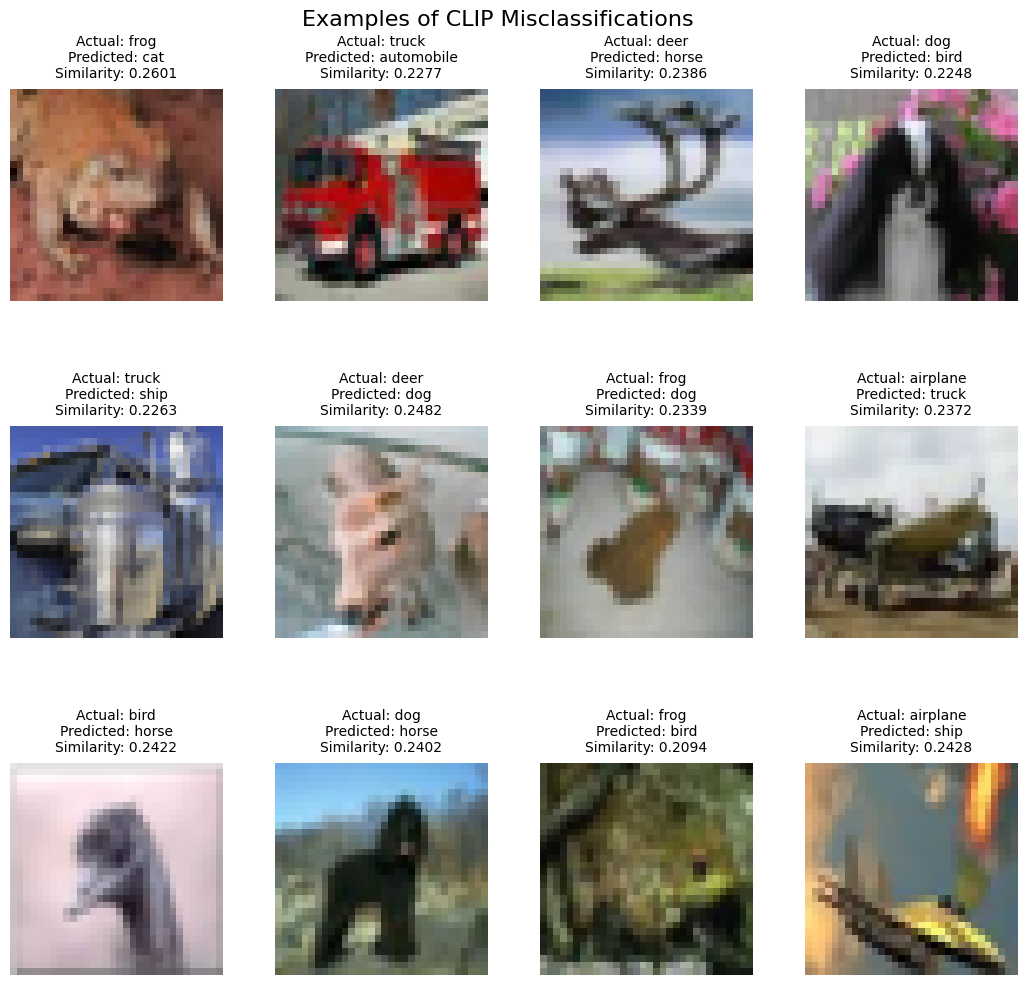


Failure analysis visualization saved!
File location: /content/drive/MyDrive/Homework11_CLIP/outputs/failure_analysis/misclassified_examples.png
File exists: True


In [19]:

# Display 12 incorrectly classified images
fig, axes = plt.subplots(3, 4, figsize=(13, 11))

for ax, index in zip(axes.flat, wrong_indices[:12]):

    # Get the numeric class IDs
    actual_id = int(actual_labels[index])
    predicted_id = int(predicted_labels[index])

    # Convert class IDs into readable names
    actual = class_names[actual_id]
    predicted = class_names[predicted_id]

    # Get the similarity score using the numeric class ID
    score = similarity_scores[index, predicted_id].item()

    # Display the incorrectly classified image
    ax.imshow(images[index])

    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Similarity: {score:.4f}",
        fontsize=10,
        pad=8
    )

    ax.axis("off")

fig.suptitle(
    "Examples of CLIP Misclassifications",
    fontsize=16,
    y=0.99
)

plt.subplots_adjust(
    top=0.92,
    hspace=0.55,
    wspace=0.25
)

# Save the visualization
figure_path = failure_dir / "misclassified_examples.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("\nFailure analysis visualization saved!")
print("File location:", figure_path)
print("File exists:", figure_path.exists())


##  Classification Evaluation Metrics

In this step, I evaluate CLIP's zero-shot classification performance using precision, recall, F1-score, and support.

Although overall accuracy measures how many images were classified correctly, these additional metrics help explain how the model performs for individual classes.

- **Precision:** Measures how many images predicted as a class actually belong to that class.
- **Recall:** Measures how many images from a class were correctly identified.
- **F1-score:** Combines precision and recall into a single score.
- **Support:** Shows the number of actual images belonging to each class.

I also calculate macro and weighted averages to summarize performance across the 10 CIFAR-10 classes.

Finally, I save the classification report and create a visualization comparing precision, recall, and F1-score for each class.

CLIP Classification Report

              precision  recall  f1-score   support
airplane         0.9785   0.910    0.9430   100.000
automobile       0.9333   0.980    0.9561   100.000
bird             0.8519   0.920    0.8846   100.000
cat              0.8318   0.890    0.8599   100.000
deer             0.9730   0.720    0.8276   100.000
dog              0.8700   0.870    0.8700   100.000
frog             0.9762   0.820    0.8913   100.000
horse            0.7752   1.000    0.8734   100.000
ship             0.9612   0.990    0.9754   100.000
truck            0.9588   0.930    0.9442   100.000
accuracy         0.9030   0.903    0.9030     0.903
macro avg        0.9110   0.903    0.9025  1000.000
weighted avg     0.9110   0.903    0.9025  1000.000


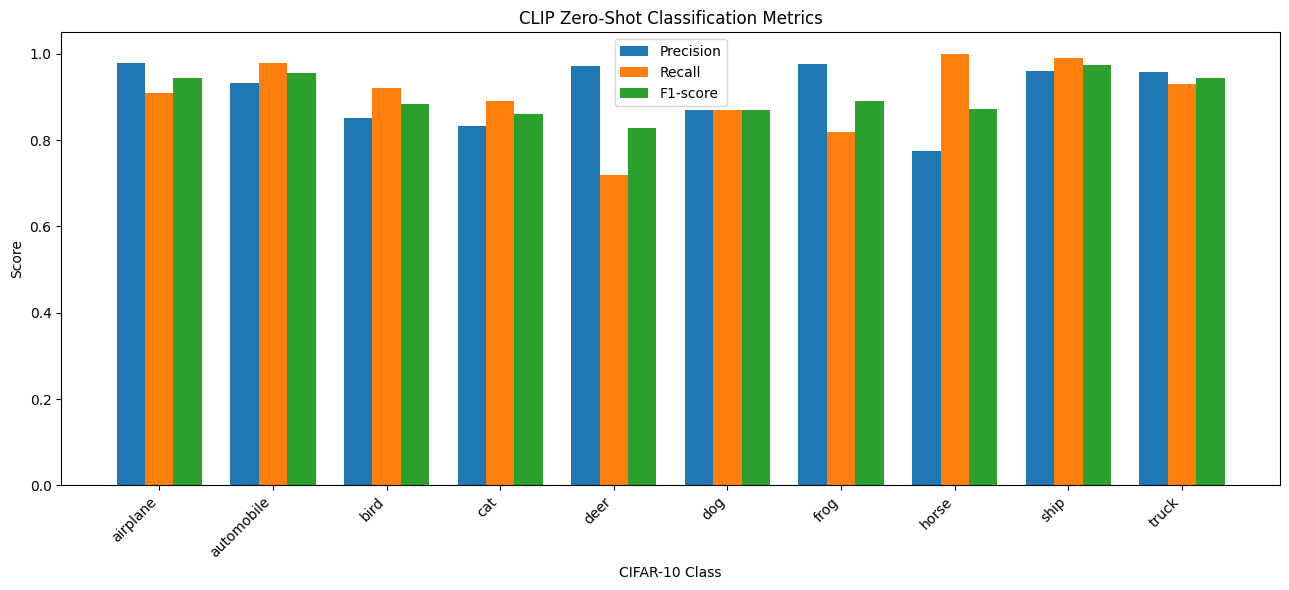


Files saved successfully!
Classification report: /content/drive/MyDrive/Homework11_CLIP/outputs/metrics/classification_report.csv
Evaluation metrics: /content/drive/MyDrive/Homework11_CLIP/outputs/metrics/evaluation_metrics.json
Metrics chart: /content/drive/MyDrive/Homework11_CLIP/outputs/metrics/precision_recall_f1.png

File verification:
CSV exists: True
JSON exists: True
PNG exists: True


In [20]:

import json
from sklearn.metrics import classification_report

# Create a folder for evaluation metrics
metrics_dir = output_dir / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

# Calculate the classification report
report = classification_report(
    actual_labels,
    predicted_labels,
    labels=range(10),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Convert the report into a table
report_df = pd.DataFrame(report).T

print("CLIP Classification Report\n")
print(report_df.round(4).to_string())

# Save the classification report as CSV
csv_path = metrics_dir / "classification_report.csv"
report_df.to_csv(csv_path)

# Save evaluation metrics as JSON
json_path = metrics_dir / "evaluation_metrics.json"

with open(json_path, "w") as file:
    json.dump(report, file, indent=4)

# Create a comparison chart
class_report = report_df.loc[class_names]

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(13, 6))

plt.bar(x - width, class_report["precision"], width, label="Precision")
plt.bar(x, class_report["recall"], width, label="Recall")
plt.bar(x + width, class_report["f1-score"], width, label="F1-score")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Score")
plt.title("CLIP Zero-Shot Classification Metrics")
plt.legend()
plt.tight_layout()

# Save the metrics visualization
png_path = metrics_dir / "precision_recall_f1.png"
plt.savefig(png_path, dpi=300, bbox_inches="tight")

plt.show()

print("\nFiles saved successfully!")
print("Classification report:", csv_path)
print("Evaluation metrics:", json_path)
print("Metrics chart:", png_path)

print("\nFile verification:")
print("CSV exists:", csv_path.exists())
print("JSON exists:", json_path.exists())
print("PNG exists:", png_path.exists())


##  Experiment Run Logs

In this step, I create a run log to record the configuration and results of my CLIP zero-shot classification experiment.

The log includes the pretrained model name, dataset information, number of classes, image count, captions, batch size, GPU details, and evaluation metrics.

I also record the locations of the saved output files.

Since I used a pretrained CLIP model without fine-tuning, there are no training epochs, training losses, or optimizer settings to report.

The run log records the environment and results available at the time of logging. It does not estimate the original execution time.

I save this information as a JSON file in Google Drive to make the experiment easier to understand and reproduce.

In [21]:

import json
import sys
import platform
from datetime import datetime, timezone
import transformers
import sklearn

# Create a folder for run logs
run_logs_dir = output_dir / "run_logs"
run_logs_dir.mkdir(parents=True, exist_ok=True)

# Record current environment information
gpu_name = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

# Record all files currently saved in the output folder
saved_files = sorted(
    str(path.relative_to(output_dir))
    for path in output_dir.rglob("*")
    if path.is_file()
)

# Create the experiment log
run_log = {
    "experiment_name": "Homework 11 - CLIP Zero-Shot Classification",
    "log_created_utc": datetime.now(timezone.utc).isoformat(),

    "model": {
        "name": model_name,
        "pretrained": True,
        "fine_tuned": False,
        "training_epochs": 0
    },

    "dataset": {
        "name": "CIFAR-10",
        "split": "test",
        "total_images": len(images),
        "number_of_classes": len(class_names),
        "images_per_class": class_counts,
        "class_names": class_names
    },

    "configuration": {
        "batch_size": batch_size,
        "captions": captions,
        "image_embedding_shape": list(image_embeddings.shape),
        "text_embedding_shape": list(text_embeddings.shape),
        "similarity_matrix_shape": list(similarity_scores.shape),
        "embedding_normalization": "L2",
        "similarity_method": "Cosine similarity",
        "classification_method": "Highest similarity caption"
    },

    "environment": {
        "python_version": sys.version.split()[0],
        "pytorch_version": torch.__version__,
        "transformers_version": transformers.__version__,
        "scikit_learn_version": sklearn.__version__,
        "platform": platform.platform(),
        "device": device,
        "gpu": gpu_name
    },

    "evaluation": {
        "total_images": int(len(actual_labels)),
        "correct_predictions": int(correct_predictions),
        "incorrect_predictions": int(incorrect_predictions),
        "overall_accuracy_percent": float(overall_accuracy * 100),
        "macro_precision": float(report["macro avg"]["precision"]),
        "macro_recall": float(report["macro avg"]["recall"]),
        "macro_f1": float(report["macro avg"]["f1-score"]),
        "weighted_f1": float(report["weighted avg"]["f1-score"])
    },

    "saved_output_files": saved_files
}

# Save the run log
log_path = run_logs_dir / "evaluation_run_log.json"

with open(log_path, "w") as file:
    json.dump(run_log, file, indent=4)

print("EXPERIMENT RUN LOG")
print("=" * 50)

print("Model:", run_log["model"]["name"])
print("Dataset:", run_log["dataset"]["name"])
print("Images:", run_log["dataset"]["total_images"])
print("GPU:", run_log["environment"]["gpu"])
print("Batch size:", run_log["configuration"]["batch_size"])
print("Training performed:", run_log["model"]["fine_tuned"])
print("Overall accuracy:", f"{overall_accuracy * 100:.2f}%")
print("Macro F1-score:", f"{run_log['evaluation']['macro_f1']:.4f}")
print("Output files recorded:", len(saved_files))

print("\nRun log saved successfully!")
print("File:", log_path)
print("File exists:", log_path.exists())


EXPERIMENT RUN LOG
Model: openai/clip-vit-base-patch32
Dataset: CIFAR-10
Images: 1000
GPU: NVIDIA L4
Batch size: 32
Training performed: False
Overall accuracy: 90.30%
Macro F1-score: 0.9025
Output files recorded: 23

Run log saved successfully!
File: /content/drive/MyDrive/Homework11_CLIP/outputs/run_logs/evaluation_run_log.json
File exists: True


##  Evaluation — Findings and Discussion

### Failure Analysis

The CLIP model correctly classified 903 out of 1,000 CIFAR-10 images and made 97 incorrect predictions.

To understand these mistakes, I examined the misclassified images and analyzed the most common class confusions.

The most frequent mistake was deer being predicted as horse, which happened 17 times. Other mistakes included 8 dog images predicted as cats, 7 frog images predicted as birds, and 6 trucks predicted as automobiles.

The misclassified-image visualization also helped me inspect individual errors. Some pictures were blurry or had visual features that could make the categories difficult to distinguish.

These observations suggest that image resolution and similarities between categories may affect CLIP's predictions, although the error counts alone do not establish the exact causes.

### Additional Evaluation Metrics

Along with overall and per-class accuracy, I calculated precision, recall, and F1-score.

The main results were:

- **Overall accuracy:** 90.30%
- **Macro precision:** 91.10%
- **Macro recall:** 90.30%
- **Macro F1-score:** 90.25%
- **Weighted F1-score:** 90.25%

An interesting result was the horse class. It achieved 100% recall but approximately 77.52% precision.

This means CLIP correctly identified all actual horse images, but it also incorrectly predicted some images from other categories as horses.

The deer class showed the opposite pattern, with approximately 97.30% precision but only 72% recall. This means most images predicted as deer were actually deer, but many actual deer images were assigned to other classes.

These results helped me understand why looking at accuracy alone does not give a complete picture of model performance.

### Experiment Reproducibility

I saved the dataset details, captions, embeddings, similarity scores, predictions, classification metrics, figures, and run logs separately in Google Drive.

I also recorded the pretrained CLIP model, batch size, GPU, library versions, and evaluation settings.

Since this was a zero-shot experiment, I did not train or fine-tune the model.

### Final Reflection

This additional analysis helped me understand both the strengths and limitations of CLIP.

The model achieved strong overall performance without additional training, but it was less accurate for certain categories, especially deer.

By examining incorrect predictions, precision, recall, and F1-score, I gained a better understanding of how to evaluate image classification models beyond overall accuracy.

##  Final Output Verification

In this step, I verify that all assignment output files are saved in Google Drive.

The files include dataset information, embeddings, similarity results, classification outputs, failure analysis, additional evaluation metrics, and run logs.

I check whether each expected file exists and confirm the total number of saved artifacts.

This ensures that the important results are preserved separately from the notebook.

In [22]:

# List all expected assignment output files
expected_files = [
    # Dataset files
    dataset_dir / "selected_labels.csv",
    dataset_dir / "class_distribution.csv",
    dataset_dir / "captions.csv",
    dataset_dir / "sample_images.png",

    # Embeddings
    embeddings_dir / "image_embeddings.npy",
    embeddings_dir / "text_embeddings.npy",

    # Similarity analysis
    similarity_dir / "similarity_scores.npy",
    similarity_dir / "similarity_scores.csv",
    similarity_dir / "top_matching_images.png",
    similarity_dir / "average_similarity.csv",
    similarity_dir / "average_similarity.png",

    # Classification
    classification_dir / "predictions.csv",
    classification_dir / "overall_accuracy.csv",
    classification_dir / "per_class_accuracy.csv",
    classification_dir / "per_class_accuracy.png",
    classification_dir / "confusion_matrix.csv",
    classification_dir / "confusion_matrix.png",

    # Failure analysis
    failure_dir / "misclassified_images.csv",
    failure_dir / "common_mistakes.csv",
    failure_dir / "misclassified_examples.png",

    # Additional metrics
    metrics_dir / "classification_report.csv",
    metrics_dir / "evaluation_metrics.json",
    metrics_dir / "precision_recall_f1.png",

    # Run logs
    run_logs_dir / "evaluation_run_log.json"
]

print("FINAL HOMEWORK 11 OUTPUT VERIFICATION")
print("=" * 55)

for file in expected_files:
    status = "FOUND" if file.is_file() else "MISSING"
    print(f"[{status}] {file.relative_to(output_dir)}")

found_count = sum(file.is_file() for file in expected_files)

print("\nTotal expected files:", len(expected_files))
print("Files found:", found_count)
print("Missing files:", len(expected_files) - found_count)

if found_count == len(expected_files):
    print("\nSUCCESS: All Homework 11 output files are saved!")
else:
    print("\nSome files are missing. Review the list above.")


FINAL HOMEWORK 11 OUTPUT VERIFICATION
[FOUND] dataset/selected_labels.csv
[FOUND] dataset/class_distribution.csv
[FOUND] dataset/captions.csv
[FOUND] dataset/sample_images.png
[FOUND] embeddings/image_embeddings.npy
[FOUND] embeddings/text_embeddings.npy
[FOUND] similarity/similarity_scores.npy
[FOUND] similarity/similarity_scores.csv
[FOUND] similarity/top_matching_images.png
[FOUND] similarity/average_similarity.csv
[FOUND] similarity/average_similarity.png
[FOUND] classification/predictions.csv
[FOUND] classification/overall_accuracy.csv
[FOUND] classification/per_class_accuracy.csv
[FOUND] classification/per_class_accuracy.png
[FOUND] classification/confusion_matrix.csv
[FOUND] classification/confusion_matrix.png
[FOUND] failure_analysis/misclassified_images.csv
[FOUND] failure_analysis/common_mistakes.csv
[FOUND] failure_analysis/misclassified_examples.png
[FOUND] metrics/classification_report.csv
[FOUND] metrics/evaluation_metrics.json
[FOUND] metrics/precision_recall_f1.png
[FOU